# Projeto Integrador IV – UNIVESP

**Objetivo:** prever a quantidade diária de doses aplicadas, comparando modelos
de séries temporais para apoiar o planejamento de estoque e equipes.

**Dados:** [fonte dos dados], período de 01/01/2026 a [data final].

**Etapas:** preparação → exploração → decomposição → modelagem → comparação → conclusão.

# 03 — Séries Temporais: Previsão de Doses Aplicadas por Imunobiológico
**Projeto:** PI4 — Vacinação Porto Alegre (PNI/2026)  
**Tabela:** `pi4-vacinacao-poa.pni_gold.tb_series_temporais_doses`

# Previsão de demanda de doses: séries temporais

Fluxo (conforme README):
```
Preparação da série → Divisão temporal treino/teste → Baseline → ARIMA → Prophet → MAE / RMSE → Comparação
```

## 1. Setup e configuração
Importamos as bibliotecas (pandas, statsmodels, prophet etc.) e carregamos a base.
As versões estão fixadas no `requirements.txt` (`pandas<3`, `cmdstanpy==1.2.5`,
`prophet==1.1.7`) por questões de compatibilidade.

In [45]:
# !pip install google-cloud-bigquery db-dtypes pandas-gbq statsmodels prophet holidays -q

import warnings, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (13, 4.5)

# ---------------- CONFIG ----------------
PROJECT_ID = "pi4-vacinacao-poa"
DATASET    = "pni_gold"
TABLE      = "tb_series_temporais_doses"

# Ajuste os nomes após rodar a célula de schema (seção 2).
# Se deixar None, o notebook tenta detectar automaticamente.
COL_DATA  = None   # ex.: "dt_vacina"
COL_VACINA = None  # ex.: "ds_vacina" / "sg_vacina"
COL_DOSES = None   # ex.: "qtd_doses"  (se None e não houver, conta linhas)

TOP_N_VACINAS = 5      # imunobiológicos modelados individualmente (+ série TOTAL)
HORIZONTE     = 28     # dias de teste / previsão (4 semanas)
SAZONALIDADE  = 7      # sazonalidade semanal (dias úteis x fim de semana)

FIG_DIR = Path("../reports/figures/series_temporais"); FIG_DIR.mkdir(parents=True, exist_ok=True)
def salvar(nome): plt.tight_layout(); plt.savefig(FIG_DIR / f"{nome}.png", dpi=120, bbox_inches="tight")

## 2. Ingestão do BigQuery

In [46]:
from google.cloud import bigquery
import pydata_google_auth
credentials = pydata_google_auth.get_user_credentials(
    ["https://www.googleapis.com/auth/bigquery"],
    auth_local_webserver=False,
)
client = bigquery.Client(project=PROJECT_ID, credentials=credentials)

schema = client.query(f'''
    SELECT column_name, data_type
    FROM `{PROJECT_ID}.{DATASET}.INFORMATION_SCHEMA.COLUMNS`
    WHERE table_name = '{TABLE}'
    ORDER BY ordinal_position
''').to_dataframe()
display(schema)

df_raw = client.query(f"SELECT * FROM `{PROJECT_ID}.{DATASET}.{TABLE}`").to_dataframe()
print(df_raw.shape); df_raw.head(10)

,column_name,data_type
0,data_aplicacao,DATE
1,ano_aplicacao,INT64
2,mes_aplicacao,INT64
3,dia_semana,INT64
4,sigla_vacina,STRING
5,tipo_dose,STRING
6,total_doses_aplicadas,INT64
7,pacientes_atendidos,INT64


(22419, 8)


,data_aplicacao,ano_aplicacao,mes_aplicacao,dia_semana,sigla_vacina,tipo_dose,total_doses_aplicadas,pacientes_atendidos
0,2026-01-02,2026,1,6,BCG,nica,57,55
1,2026-01-02,2026,1,6,COV-19 PFIZER-COMIRN,Dose,107,107
2,2026-01-02,2026,1,6,HB,1 Dose,76,76
3,2026-01-02,2026,1,6,dT,1 Dose,67,67
4,2026-01-02,2026,1,6,dT,Reforo,63,63
5,2026-01-03,2026,1,7,HB,Dose,61,59
6,2026-01-05,2026,1,2,BCG,nica,100,99
7,2026-01-05,2026,1,2,COV-19 PFIZER-COMIRN,Dose,194,194
8,2026-01-05,2026,1,2,DNG,2 Dose,67,67
9,2026-01-05,2026,1,2,DNG,1 Dose,88,88


In [47]:
# Cópia de trabalho: as correções são aplicadas no df, e o df_raw fica intacto
df = df_raw.copy()
print(df.shape)

(22419, 8)


In [48]:
# Coluna de data: usa COL_DATA se estiver definida, senão detecta
col_data = COL_DATA or next(
    c for c in df_raw.columns
    if "data" in c.lower() or c.lower().startswith("dt")
)
datas = pd.to_datetime(df_raw[col_data])
print("Coluna de data:", col_data)

dias = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

# Número de linhas por dia da semana
display(datas.dt.day_name().value_counts().reindex(dias).rename("linhas"))

# Doses por dia da semana (se houver coluna de doses)
col_doses = COL_DOSES or next(
    (c for c in df_raw.columns if "dose" in c.lower() or c.lower().startswith("qt")), None
)
if col_doses:
    display(df_raw.groupby(datas.dt.day_name())[col_doses].sum().reindex(dias).rename("doses"))

Coluna de data: data_aplicacao


data_aplicacao
Monday       3779
Tuesday      3685
Wednesday    3826
Thursday     3765
Friday       3829
Saturday     2536
Sunday        999
Name: linhas, dtype: int64

data_aplicacao
Monday       nicaDose2 Dose1 Dose1 Reforonica3 Dose1 Dose2 ...
Tuesday      nicaDose1 Dosenica1 Dose2 DoseDosenicanicaRefo...
Wednesday    Dose1 Dose1 DoseDose2 DosenicaReforo2 Dose1 Do...
Thursday     Dose2 Dose1 Dose1 Reforo1 DoseDose2 Dosenica3 ...
Friday       nicaDose1 Dose1 DoseReforonicaDose1 Dose2 Dose...
Saturday     DosenicaDosenicanicanicanica2 DoseDosenica2 Do...
Sunday       DosenicanicanicaDosenicanicanicanicanicanicani...
Name: doses, dtype: object

In [49]:
# Correção de acentos perdidos na carga dos dados (coluna tipo_dose)
antes = df['tipo_dose'].nunique()

s = df['tipo_dose'].str.strip()
s = s.str.replace(r'^nica$', 'Única', regex=True)
s = s.str.replace('Reforo', 'Reforço', regex=False)
s = s.str.replace('Revacinao', 'Revacinação', regex=False)
s = s.str.replace(r'^(\d) Dose', r'\1ª Dose', regex=True)
s = s.str.replace(r'^(\d) Reforço', r'\1º Reforço', regex=True)
df['tipo_dose'] = s

# Conferência: a quantidade de categorias deve continuar igual (36)
assert df['tipo_dose'].nunique() == antes, "Duas categorias se juntaram, verifique!"
print(df['tipo_dose'].value_counts().to_string())

tipo_dose
1ª Dose                                  5832
2ª Dose                                  5083
Única                                    2572
3ª Dose                                  2238
Reforço                                  1705
Dose                                     1445
1º Reforço                               1155
Profilaxia/Tratamento com 1 unidade       501
2º Reforço                                471
4ª Dose                                   167
1ª Dose Revacinação                       150
2ª Dose Dobrada                           145
4ª Dose Dobrada                           143
1ª Dose Dobrada                           141
3ª Dose Dobrada                           137
Revacinação                               103
Dose Zero                                  67
2ª Dose Revacinação                        53
1ª Dose Revacinação Dobrada                47
Profilaxia/Tratamento com 2 unidades       45
Dose Adicional                             44
4ª Dose Revacinação Dobr

Os dados foram obtidos do BigQuery (projeto `pi4-vacinacao-poa`).
A base tem **22.419 registros e 8 colunas**: data da aplicação, ano, mês, dia da semana, vacina (`sigla_vacina`), tipo de dose, total de doses aplicadas e pacientes atendidos.

**Leitura inicial:**
- Cada registro é a combinação de **dia + vacina + tipo de dose**. Para a   análise de série temporal, as doses serão somadas por dia.
- Os dados começam em **01/01/2026**.
- A distribuição de registros por dia da semana mostra atividade concentrada de **segunda a sexta** (cerca de 3.700 a 3.900 registros por dia), queda no
  **sábado** (2.536) e volume bem menor no **domingo** (999). Isso indica funcionamento reduzido nos fins de semana, o que deve aparecer como   **sazonalidade semanal** na série temporal.
- O total de doses é quase igual ao número de pacientes atendidos, então é raro alguém receber mais de uma dose da mesma vacina no mesmo dia.
- A coluna `tipo_dose` veio com caracteres acentuados perdidos (ex.: "nica", "Reforo", "1 Dose"), provavelmente por problema de codificação na carga para
  o BigQuery. Os valores foram corrigidos no notebook ("Única", "Reforço", "1ª Dose" etc.), mantendo as 36 categorias originais. A coluna `sigla_vacina` não teve problemas.
- A categoria "Dose" (sem complemento) foi mantida como está, pois não foi possível confirmar o valor original.


### 2.1 Detecção das colunas-chave
Definimos as colunas usadas nas próximas etapas:
- **data:** `data_aplicacao`, o eixo temporal da série;
- **vacina:** `sigla_vacina`, usada para análises por imunizante;
- **doses:** `total_doses_aplicadas`, a variável que será prevista.

A coluna `pacientes_atendidos` não foi usada como alvo porque é quase igual
ao total de doses.

In [50]:
def detectar(df, candidatos, tipo=None):
    cols = [c for c in df.columns if any(k in c.lower() for k in candidatos)]
    if tipo == "data":
        cols = [c for c in cols if pd.api.types.is_datetime64_any_dtype(df[c]) or df[c].dtype == object] or cols
    if tipo == "num":
        cols = [c for c in cols if pd.api.types.is_numeric_dtype(df[c])]
    return cols[0] if cols else None

COL_DATA   = COL_DATA   or detectar(df_raw, ["data", "dt_", "dia", "date"], "data")
COL_VACINA = COL_VACINA or detectar(df_raw.drop(columns=[COL_DATA]).select_dtypes(exclude=["number","datetime"]),
                                     ["vacina", "imuno", "sg_", "ds_"])
COL_DOSES  = COL_DOSES  or detectar(df_raw, ["dose", "qtd", "total", "quant", "count"], "num")
print(f"data={COL_DATA} | vacina={COL_VACINA} | doses={COL_DOSES}")
assert COL_DATA and COL_VACINA, "Defina COL_DATA e COL_VACINA manualmente na célula de CONFIG."

data=data_aplicacao | vacina=sigla_vacina | doses=total_doses_aplicadas


## 3. Validação estrutural

In [51]:
df = df_raw.copy()
df[COL_DATA] = pd.to_datetime(df[COL_DATA], errors="coerce")
if COL_DOSES is None:
    df["_doses"] = 1; COL_DOSES = "_doses"

print("Nulos por coluna:\n", df.isna().sum(), "\n")
print("Datas inválidas:", df[COL_DATA].isna().sum())
print("Período:", df[COL_DATA].min().date(), "→", df[COL_DATA].max().date())
print("Imunobiológicos distintos:", df[COL_VACINA].nunique())
print("Doses negativas:", (df[COL_DOSES] < 0).sum())
dup = df.duplicated(subset=[COL_DATA, COL_VACINA]).sum()
print("Linhas duplicadas (data × vacina):", dup, "→ serão somadas na agregação" if dup else "")

dias = pd.date_range(df[COL_DATA].min(), df[COL_DATA].max(), freq="D")
faltantes = dias.difference(df[COL_DATA].dropna().unique())
print(f"Dias sem nenhum registro: {len(faltantes)}", list(faltantes.date[:10]))

# Aviso: o último mês costuma estar incompleto (atraso de digitação no SI-PNI)
ult = df.groupby(COL_DATA)[COL_DOSES].sum().tail(14); print("\nÚltimos 14 dias:\n", ult)

Nulos por coluna:
 data_aplicacao           0
ano_aplicacao            0
mes_aplicacao            0
dia_semana               0
sigla_vacina             0
tipo_dose                0
total_doses_aplicadas    0
pacientes_atendidos      0
dtype: int64 

Datas inválidas: 0
Período: 2026-01-01 → 2026-07-31
Imunobiológicos distintos: 65
Doses negativas: 0
Linhas duplicadas (data × vacina): 14025 → serão somadas na agregação
Dias sem nenhum registro: 0 []

Últimos 14 dias:
 data_aplicacao
2026-07-18     889
2026-07-19     288
2026-07-20    2780
2026-07-21    2344
2026-07-22    3231
2026-07-23    3195
2026-07-24    4096
2026-07-25     756
2026-07-26     287
2026-07-27    4584
2026-07-28    2859
2026-07-29    3836
2026-07-30    3676
2026-07-31    4147
Name: total_doses_aplicadas, dtype: Int64


**Verificação da qualidade dos dados**

A base não apresenta valores nulos, datas inválidas ou doses negativas.
O período vai de **01/01/2026 a 31/07/2026** (212 dias), sem nenhum dia
faltando, então não foi preciso preencher lacunas na série.

As 14.025 linhas com a mesma combinação de data e vacina não são erros:
correspondem a tipos de dose diferentes da mesma vacina no mesmo dia e
serão somadas na agregação diária.

Os últimos 14 dias já mostram uma **sazonalidade semanal** forte: nos dias
úteis são aplicadas entre 2.300 e 4.600 doses, no sábado entre 750 e 900 e
no domingo cerca de 290. Esse padrão de período 7 deve ser considerado nos
modelos (por exemplo, com sazonalidade semanal no SARIMA ou no Prophet).


## 4. Preparação da série (diária, datas completas)

In [52]:
df = df.dropna(subset=[COL_DATA])
serie_total = df.groupby(COL_DATA)[COL_DOSES].sum().asfreq("D", fill_value=0)

top = df.groupby(COL_VACINA)[COL_DOSES].sum().sort_values(ascending=False)
vacinas_top = top.head(TOP_N_VACINAS).index.tolist()
print("Participação dos Top imunobiológicos (%):"); display((top / top.sum() * 100).head(15).round(2))

pivot = (df[df[COL_VACINA].isin(vacinas_top)]
         .pivot_table(index=COL_DATA, columns=COL_VACINA, values=COL_DOSES, aggfunc="sum")
         .asfreq("D").fillna(0))
series = {"TOTAL": serie_total, **{v: pivot[v] for v in vacinas_top}}

Participação dos Top imunobiológicos (%):


sigla_vacina
INF3                    41.71
INF4                     10.8
COV-19 PFIZER-COMIRN     7.89
HB                       4.76
dT                       4.26
VIP                      2.61
MenACWY                  2.01
DNG                      1.97
VPC20                    1.87
VFA                      1.87
SCR                      1.83
Penta                    1.73
VPC10                    1.35
BCG                      1.29
HPV4                     1.18
Name: total_doses_aplicadas, dtype: Float64

**Participação das vacinas no total de doses**

A distribuição das doses é bastante concentrada. A vacina contra influenza
trivalente (INF3) responde sozinha por **41,7%** do total e, somada à
quadrivalente (INF4), a **influenza chega a cerca de 52,5%** das doses
aplicadas no período. Em seguida vêm COVID-19 Pfizer (7,9%), hepatite B
(4,8%) e dT (4,3%). As 15 vacinas mais aplicadas somam cerca de 87% do total.

A INF3 tem poucos registros (454) mas muitas doses, o que indica aplicação
concentrada em poucos dias, típica de **campanha de vacinação**. Por isso, a
série diária total deve mostrar um pico no período da campanha, e esse ponto
será avaliado na análise exploratória e considerado na modelagem.

## 5. EDA temporal

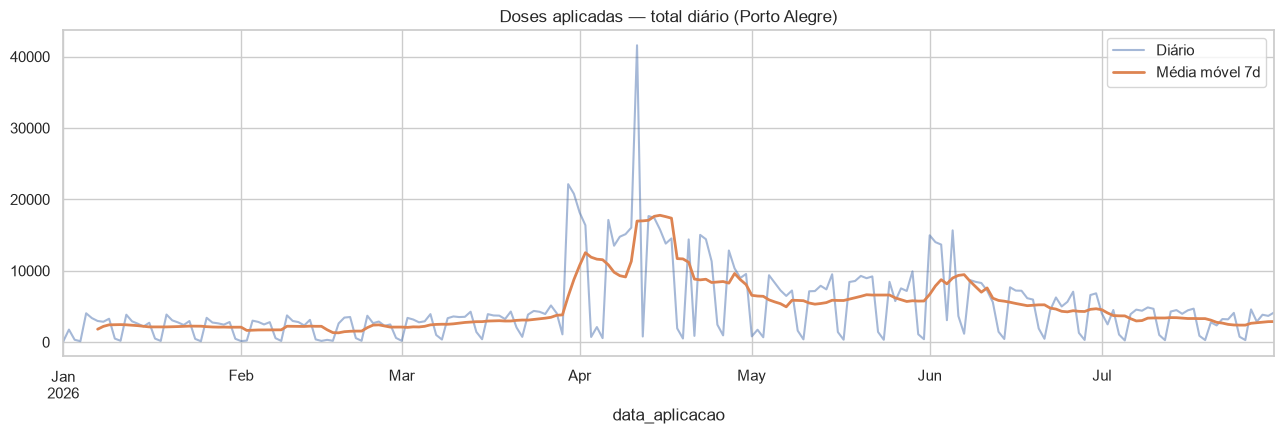

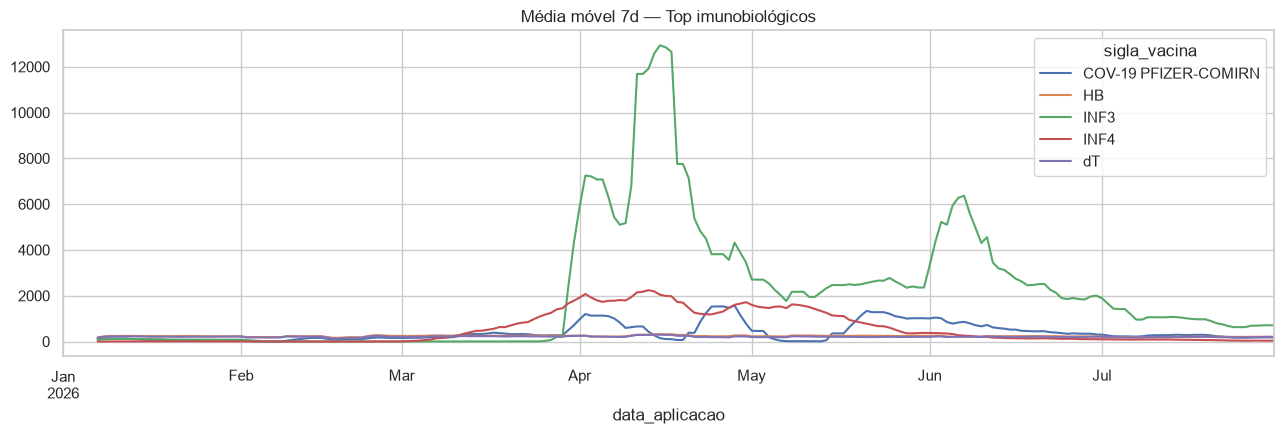

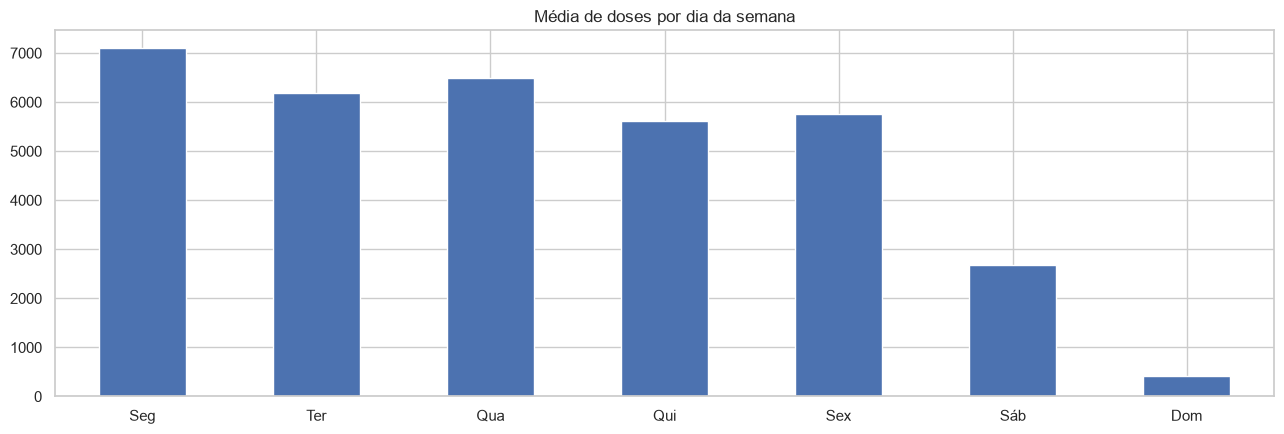

In [53]:
fig, ax = plt.subplots()
serie_total.plot(ax=ax, alpha=.5, label="Diário")
serie_total.rolling(7).mean().plot(ax=ax, lw=2, label="Média móvel 7d")
ax.set_title("Doses aplicadas — total diário (Porto Alegre)"); ax.legend(); salvar("01_total_diario")

(pivot.rolling(7).mean()).plot(title="Média móvel 7d — Top imunobiológicos"); salvar("02_top_vacinas")

nomes = {0:"Seg", 1:"Ter", 2:"Qua", 3:"Qui", 4:"Sex", 5:"Sáb", 6:"Dom"}
dow = serie_total.groupby(serie_total.index.dayofweek).mean()
dow = dow.reindex(range(7))              # garante os 7 dias (Dom fica vazio)
dow.index = [nomes[i] for i in dow.index]
fig, ax = plt.subplots()
dow.plot(kind="bar", ax=ax, title="Média de doses por dia da semana")
ax.set_xlabel(""); plt.xticks(rotation=0)
salvar("03_dia_semana")

ADF p-valor = 0.3683 → não estacionária (diferenciar)


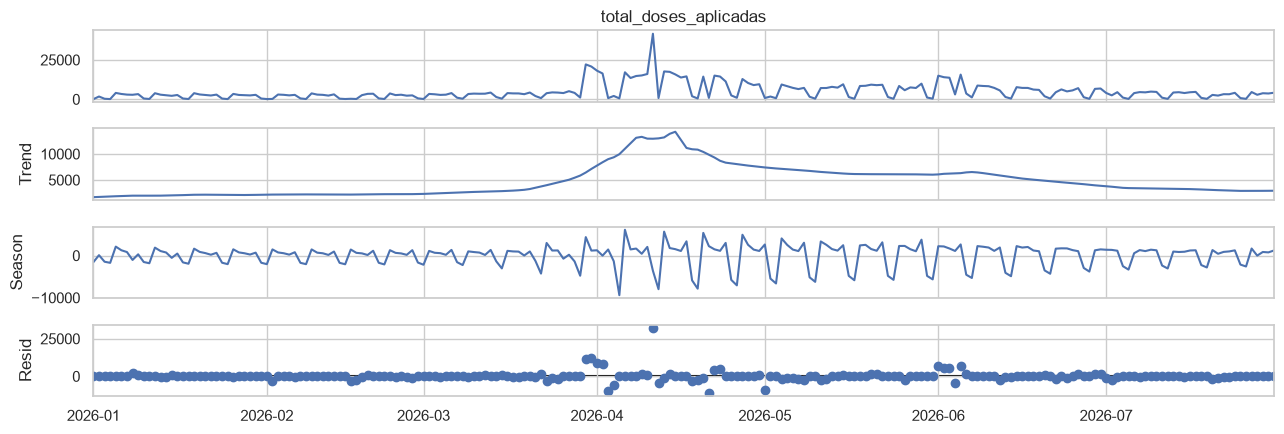

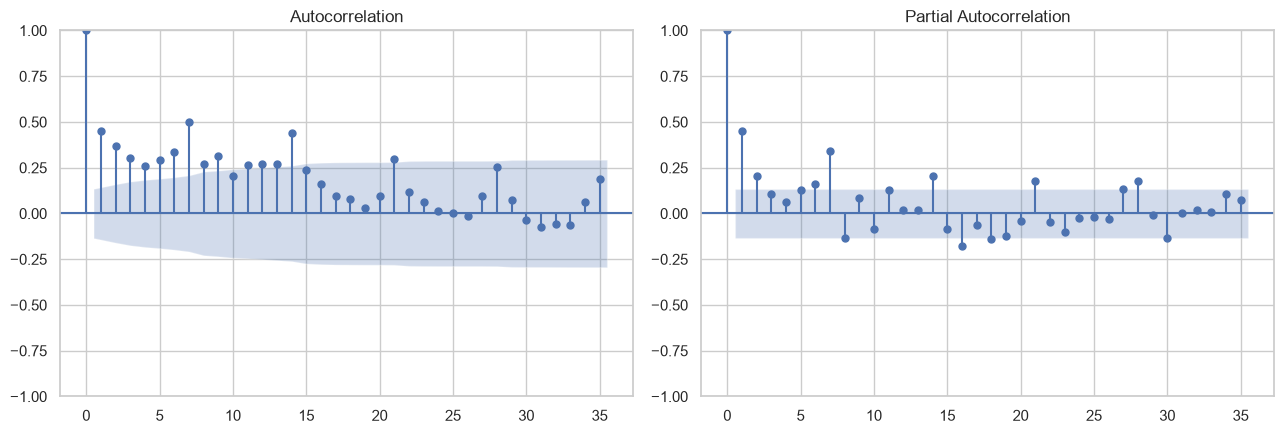

In [54]:
stl = STL(serie_total, period=SAZONALIDADE, robust=True).fit()
stl.plot(); salvar("04_decomposicao_stl")

adf = adfuller(serie_total)
print(f"ADF p-valor = {adf[1]:.4f} →", "estacionária" if adf[1] < .05 else "não estacionária (diferenciar)")

fig, axs = plt.subplots(1, 2)
plot_acf(serie_total, lags=35, ax=axs[0]); plot_pacf(serie_total, lags=35, ax=axs[1]); salvar("05_acf_pacf")

**Análise exploratória**

A série diária mostra um pico muito acima do normal entre **abril e maio**,
concentrado principalmente em abril, com dias passando de **40.000 doses**,
cerca de 10 vezes o volume de um dia útil comum (3.000–4.500 doses). O
gráfico por imunobiológico mostra que esse pico vem principalmente da
**INF3**, o que confirma o efeito da **campanha de vacinação contra a gripe**
já sugerido na etapa 4. Fora desse período, a série fica relativamente
estável.

A média por dia da semana confirma a sazonalidade semanal: volume alto de
segunda a sexta, queda no sábado e volume mínimo no domingo. As médias ficam
acima dos valores de dias comuns porque incluem os dias de campanha.

Na série diferenciada, a ACF mostra autocorrelação significativa nas
primeiras defasagens, com destaque para o **lag [7 / 7 e 14]**, o que
confirma a **sazonalidade de período 7**. Nas defasagens maiores, as
autocorrelações ficam dentro do intervalo de confiança, o que indica que a
dependência diminui com o tempo e que a série diferenciada é
aproximadamente **estacionária**, adequada para modelos da família ARIMA.


**Implicações para a modelagem:**
- usar modelos com componente sazonal semanal (SARIMA com s = 7 e Prophet
  com sazonalidade semanal);
- tratar o período da campanha de gripe como **evento/variável indicadora**,
  para que o pico não distorça a tendência nem as previsões dos demais
  meses;
- como a série tem só 7 meses, a campanha aparece **uma única vez**, e o
  modelo não consegue aprender que ela se repete todo ano. Isso deve ser
  citado como limitação.


## 6. Divisão temporal treino/teste
Sem embaralhar: as últimas `HORIZONTE` observações são o teste.

In [55]:
def split(s, h=HORIZONTE): return s.iloc[:-h], s.iloc[-h:]
tr, te = split(serie_total)
print(f"Treino: {tr.index.min().date()} → {tr.index.max().date()} ({len(tr)} dias)")
print(f"Teste : {te.index.min().date()} → {te.index.max().date()} ({len(te)} dias)")

Treino: 2026-01-01 → 2026-07-03 (184 dias)
Teste : 2026-07-04 → 2026-07-31 (28 dias)


**Divisão em treino e teste**

A série foi dividida respeitando a ordem temporal, sem embaralhamento:
- **Treino:** 01/01/2026 a 03/07/2026 (184 dias, ~87%);
- **Teste:** 04/07/2026 a 31/07/2026 (28 dias, ~13%).

O conjunto de teste tem exatamente **4 semanas completas**, então cada dia
da semana aparece 4 vezes e a avaliação fica equilibrada em relação à
sazonalidade semanal. O horizonte de 28 dias também corresponde a uma
previsão de cerca de um mês, útil para o planejamento operacional.

O pico da campanha de influenza (abril–maio) fica inteiramente no treino, e
o teste corresponde a um período de operação normal. Assim, a avaliação
mede a capacidade dos modelos de prever a rotina, mas o pico no treino pode
distorcer o nível estimado, e por isso ele será tratado na modelagem.


## 7. Métricas e Baselines

In [56]:
def metricas(y, yhat):
    y, yhat = np.asarray(y, float), np.clip(np.asarray(yhat, float), 0, None)
    smape = np.mean(2*np.abs(yhat-y) / np.where((np.abs(y)+np.abs(yhat))==0, 1, np.abs(y)+np.abs(yhat))) * 100
    return {"MAE": mean_absolute_error(y, yhat),
            "RMSE": np.sqrt(mean_squared_error(y, yhat)),
            "sMAPE_%": smape}

def baseline_naive(tr, h):          return np.repeat(tr.iloc[-1], h)
def baseline_sazonal(tr, h, s=SAZONALIDADE):  # repete a última semana
    return np.resize(tr.iloc[-s:].values, h)
def baseline_media_dow(tr, h):      # média por dia da semana nas últimas 4 semanas
    ult = tr.iloc[-28:]; m = ult.groupby(ult.index.dayofweek).mean()
    idx = pd.date_range(tr.index[-1] + pd.Timedelta(days=1), periods=h)
    return m.reindex(idx.dayofweek).values

**Métricas de avaliação e modelos de base**

**Métricas.** Os modelos são comparados no conjunto de teste (28 dias) com:
- **MAE** (erro absoluto médio): quantas doses, em média, a previsão erra
  por dia. É a métrica principal, por ser fácil de interpretar;
- **RMSE** (raiz do erro quadrático médio): pesa mais os erros grandes e
  mostra se o modelo erra muito em alguns dias;
- **sMAPE** (erro percentual simétrico): mede o erro em termos relativos.
  Foi escolhido no lugar do MAPE porque não "explode" em dias de volume
  baixo, como os domingos (~290 doses), e fica limitado entre 0% e 200%.

Previsões negativas são ajustadas para zero antes do cálculo, já que não
existem doses negativas.

**Modelos de base (baselines).** Servem de referência mínima:
- **Naive:** repete o último valor do treino (03/07, uma sexta-feira) em
  todos os dias. Ignora a sazonalidade semanal e deve ter o pior desempenho;
- **Naive sazonal:** repete a última semana do treino, reproduzindo o
  padrão semanal;
- **Média por dia da semana:** usa a média de cada dia da semana nas
  últimas 4 semanas do treino. Suaviza dias atípicos e usa só dados
  posteriores à campanha de influenza.

Um modelo só será considerado útil se tiver MAE menor que o do melhor
baseline.


## 8. ARIMA / SARIMA
Busca em grade pequena por AIC, com sazonalidade semanal `s=7`.

In [57]:
import itertools, warnings

def ajustar_sarima(tr, s=SAZONALIDADE):
    melhor = (np.inf, None, None, None)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for p, d, q in itertools.product(range(3), range(2), range(3)):
            for P, D, Q in itertools.product(range(2), range(2), range(2)):
                try:
                    m = SARIMAX(tr, order=(p,d,q), seasonal_order=(P,D,Q,s),
                                enforce_stationarity=False,
                                enforce_invertibility=False).fit(disp=False)
                    if m.aic < melhor[0]:
                        melhor = (m.aic, (p,d,q), (P,D,Q,s), m)
                except Exception:
                    pass
    if melhor[3] is None:
        raise RuntimeError("Nenhum SARIMA convergiu.")
    return melhor[3], melhor[1], melhor[2]

def prev_sarima(tr, h):
    m, o, so = ajustar_sarima(tr)
    return np.clip(m.forecast(h).values, 0, None), f"SARIMA{o}x{so}", m

SARIMA(2, 1, 1)x(1, 1, 1, 7)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0850      0.089      0.952      0.341      -0.090       0.260
ar.L2          0.1123      0.130      0.864      0.388      -0.143       0.367
ma.L1         -0.8231      0.076    -10.785      0.000      -0.973      -0.674
ar.S.L7       -0.0656      0.066     -0.995      0.320      -0.195       0.064
ma.S.L7       -0.8528      0.061    -13.952      0.000      -0.973      -0.733
sigma2      1.882e+07   7.63e-09   2.47e+15      0.000    1.88e+07    1.88e+07
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.7533      0.047    -15.860      0.000      -0.846      -0.660
ma.S.L7       -0.8611      0.071    -12.171      0.000      -1.000      -0.722
sigma2      3.703e+07  

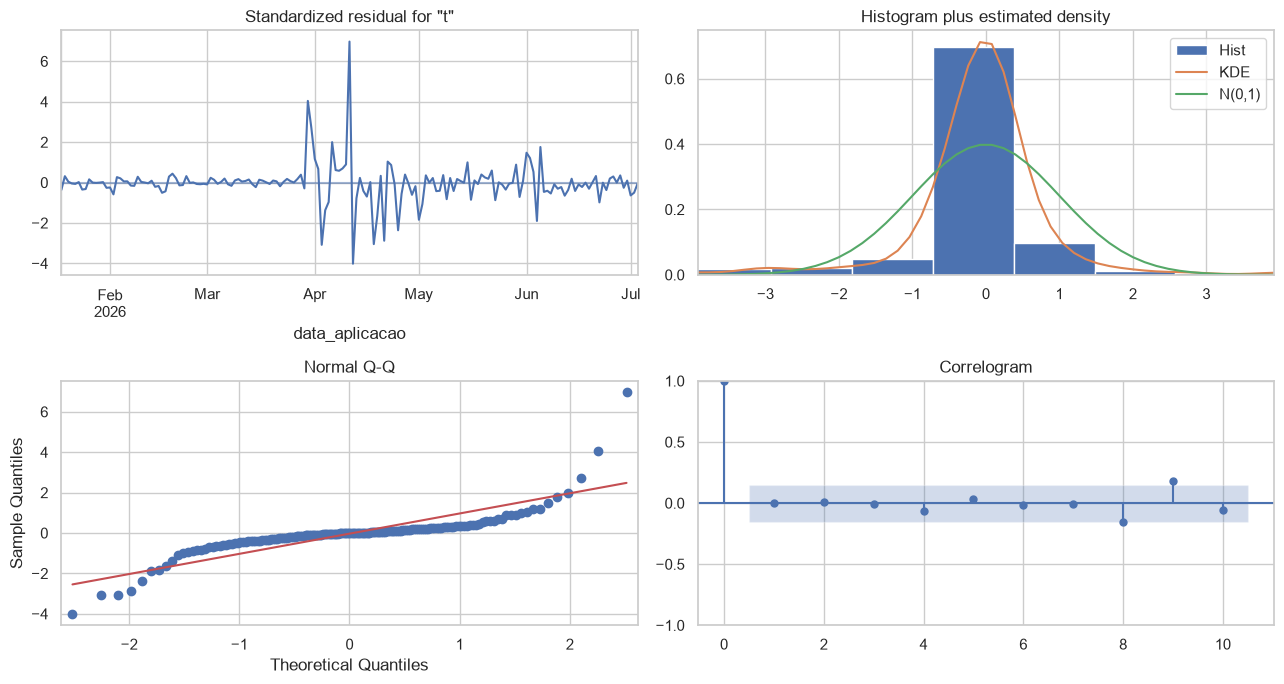

In [58]:
yhat, nome, m_total = prev_sarima(tr, HORIZONTE)
print(nome)
print(m_total.summary().tables[1])

fig = m_total.plot_diagnostics(figsize=(13, 7))
fig.tight_layout()
salvar("06_sarima_diagnostico")

# 2) Modelo simples, com as mesmas opções
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    m_simples = SARIMAX(tr, order=(0,1,1), seasonal_order=(0,1,1,SAZONALIDADE),
                        enforce_stationarity=False,
                        enforce_invertibility=False).fit(disp=False)
yhat_simples = np.clip(m_simples.forecast(HORIZONTE).values, 0, None)

print(m_simples.summary().tables[1])
print(f"AIC  {nome}: {m_total.aic:.1f} | SARIMA(0,1,1)x(0,1,1,7): {m_simples.aic:.1f}")
print("Selecionado:", metricas(te, yhat))
print("Simples    :", metricas(te, yhat_simples))

yhat_sarima, nome_sarima, m_sarima = yhat_simples, "SARIMA(0,1,1)x(0,1,1,7)", m_simples

res = pd.DataFrame({"real": te.values, "prev": yhat_sarima}, index=te.index)
res["smape"] = 200*abs(res.prev-res.real)/(res.real+res.prev).replace(0, 1)
print(res.groupby(res.index.day_name())[["real","prev","smape"]].mean().round(1))

**Modelo SARIMA**

A ordem foi escolhida por busca em grade pelo menor AIC, resultando em um
SARIMA(0,1,2)(0,1,1)₇. O termo MA(2) não foi significativo (p = 0,46), por
isso também foi ajustado o modelo simplificado SARIMA(0,1,1)(0,1,1)₇, com as
mesmas opções de estimação.

| Modelo | AIC | MAE | RMSE | sMAPE |
|---|---|---|---|---|
| SARIMA(0,1,2)(0,1,1)₇ | 3184,7 | 419 | 548 | 84,7% |
| SARIMA(0,1,1)(0,1,1)₇ | 3200,9 | 383 | 503 | 82,9% |

O modelo da busca tem AIC um pouco menor, ou seja, ajusta melhor o treino.
Mesmo assim, o modelo simples erra menos no teste em todas as métricas e
tem menos parâmetros, por isso foi escolhido. O MA sazonal próximo de −1
(−1,13) indica um padrão semanal muito estável.

**Análise dos erros por dia da semana.** O sMAPE alto vem dos fins de
semana: o modelo previu valores negativos, ajustados para zero, e o sMAPE
nesses dias chegou a 200%. Nos dias úteis, o erro percentual fica entre 9%
e 64%, com superestimação às segundas e terças. O teste (julho) tem volume
bem menor que o restante da série (~1.000–1.250 doses nos dias úteis), e
o modelo, com a amplitude semanal aprendida num período de volume alto,
não se ajusta bem a esse nível.

**Diagnóstico dos resíduos:** o correlograma não mostra autocorrelação
significativa; os valores extremos se concentram entre abril e maio
(campanha de influenza); e o gráfico Q-Q mostra caudas pesadas, então os
intervalos de previsão devem ser interpretados com cautela.

Uma possível melhoria é modelar a série em escala logarítmica, o que
impede previsões negativas e torna a sazonalidade proporcional ao nível.


## 9. Prophet
Sazonalidade semanal + feriados nacionais (BR). Sazonalidade anual desligada: há menos de 1 ano de dados.

Prophet: {'MAE': 750.496538996138, 'RMSE': np.float64(937.3290225184755), 'sMAPE_%': np.float64(33.37785838384159)}
SARIMA : {'MAE': 768.3629559533199, 'RMSE': np.float64(941.4972607085044), 'sMAPE_%': np.float64(72.85554445695487)}
                  real    prev  smape
data_aplicacao                       
Friday          4400.0  3239.4   32.6
Monday          3891.0  4155.4   27.0
Saturday         928.0  1975.7   71.1
Sunday           272.2   171.2   46.5
Thursday        4049.0  3040.3   29.6
Tuesday         3561.0  3726.1   14.4
Wednesday       3858.0  3531.2   12.5


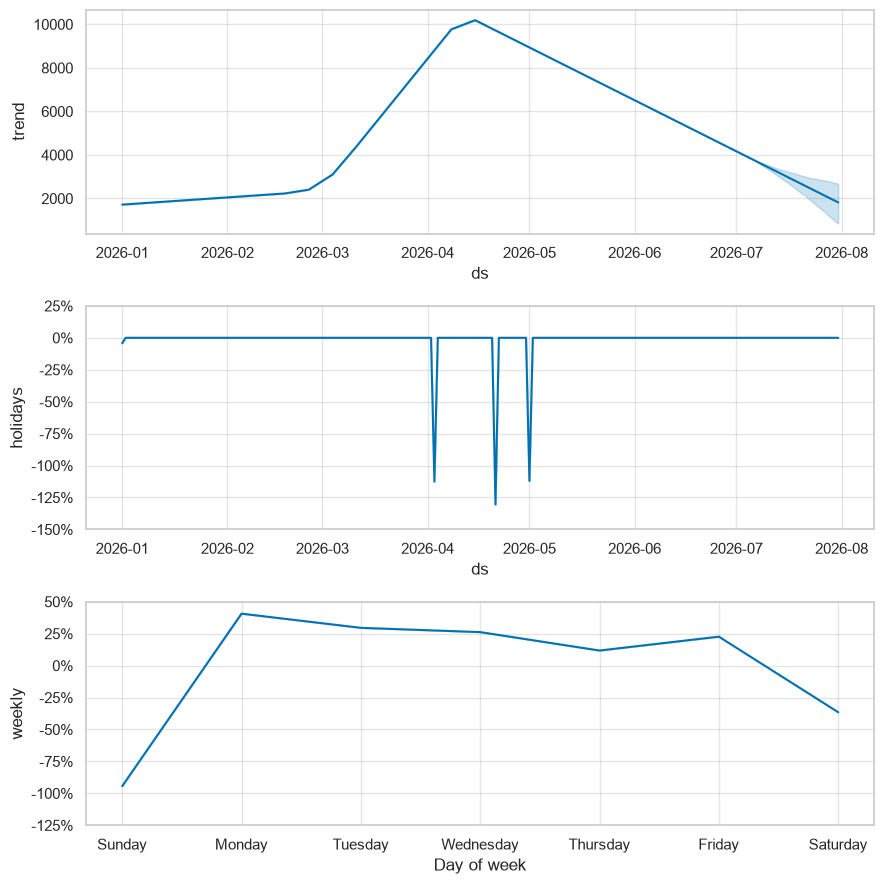

In [59]:
from prophet import Prophet
import holidays as hol
import logging
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
logging.getLogger("cmdstanpy").disabled = True


# Tabela de feriados BR, sem repetições
anos = range(tr.index.min().year, tr.index.max().year + 2)
feriados_br = pd.DataFrame(
    [(pd.Timestamp(d), nome) for d, nome in hol.Brazil(years=anos).items()],
    columns=["ds", "holiday"]
).drop_duplicates(subset="ds").reset_index(drop=True)

def prev_prophet(tr, h, retornar_modelo=False):
    d = tr.astype(float).rename_axis("ds").reset_index(name="y")
    m = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False,
                seasonality_mode="multiplicative", holidays=feriados_br,
                changepoint_range=0.95, changepoint_prior_scale=0.1)
    m.fit(d)
    fc = m.predict(m.make_future_dataframe(periods=h, include_history=False))
    return (fc, m) if retornar_modelo else np.clip(fc["yhat"].values, 0, None)

fc, m_p = prev_prophet(tr, HORIZONTE, retornar_modelo=True)
yhat_prophet = np.clip(fc["yhat"].values, 0, None)
m_p.plot_components(m_p.predict(m_p.make_future_dataframe(HORIZONTE))); salvar("07_prophet_componentes")

print("Prophet:", metricas(te, yhat_prophet))
print("SARIMA :", metricas(te, yhat_sarima))

res_p = pd.DataFrame({"real": te.values, "prev": yhat_prophet}, index=te.index)
res_p["smape"] = 200*abs(res_p.prev-res_p.real)/(res_p.real+res_p.prev).replace(0, 1)
print(res_p.groupby(res_p.index.day_name())[["real","prev","smape"]].mean().round(1))


Foi ajustado um modelo Prophet com sazonalidade semanal multiplicativa,
sem sazonalidade anual (a série tem menos de um ano) e com feriados
nacionais brasileiros.

Na primeira versão, com os parâmetros padrão de tendência
(changepoint_range = 0,8), as previsões ficaram de 3 a 4 vezes acima do
real (MAE de 2.191 doses). Por padrão, o Prophet só coloca pontos de
mudança da tendência nos primeiros 80% do treino, e a queda de volume
depois da campanha de influenza ficou fora desse trecho. Com
changepoint_range = 0,95, a tendência passou a capturar essa queda e o
MAE caiu para 624 doses (−72%). Um prior mais flexível
(changepoint_prior_scale = 0,5) não reduziu o MAE de forma relevante e
piorou o sMAPE (139%), por isso foi mantido o valor 0,1.

O gráfico de componentes mostra:
- **Tendência:** alta entre abril e maio (campanha de influenza) e queda
  no fim do treino;
- **Feriados:** quedas de até ~80% nos feriados nacionais (Sexta-feira
  Santa, Tiradentes e Dia do Trabalho);
- **Sazonalidade semanal:** volume maior nos dias úteis e queda de
  ~80% a 100% nos fins de semana.

| Modelo | MAE | RMSE | sMAPE |
|---|---|---|---|
| SARIMA(0,1,1)(0,1,1)₇ | 383 | 503 | 82,9% |
| Prophet (padrão) | 2.191 | 2.450 | 112,8% |
| Prophet (changepoint_range = 0,95) | 624 | 759 | 80,3% |

Mesmo depois do ajuste, o SARIMA teve menor erro absoluto e foi mais
preciso em todos os dias úteis. O Prophet superestimou os dias úteis em
15% a 110% e previu cerca de 1.190 doses aos sábados, contra 225 reais.
O sMAPE um pouco menor do Prophet vem só do sábado: o SARIMA previu zero
nesse dia (sMAPE de 200%), e o Prophet, um valor positivo mas muito alto
(sMAPE de 136%). Em doses, o erro do Prophet no sábado foi maior.

A sazonalidade multiplicativa não impediu previsões negativas: o efeito
semanal do domingo passa de −100%, o que torna a previsão negativa
(ajustada para zero), como no SARIMA.

Os dois modelos superestimaram segundas e terças em cerca de duas
vezes, o que indica uma mudança no padrão semanal em julho, com volume
mais homogêneo entre os dias úteis, que nenhum dos modelos consegue
antecipar a partir do treino.

Como o changepoint_range foi ajustado com base no desempenho no teste,
o resultado do Prophet pode estar levemente otimista.

## 10. Comparação dos modelos (todas as séries)

In [60]:
def prev_sarima_simples(tr, h):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = SARIMAX(tr, order=(0,1,1), seasonal_order=(0,1,1,SAZONALIDADE),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    return np.clip(m.forecast(h).values, 0, None)

resultados, previsoes = [], {}
for nome_serie, s in series.items():
    tr_s, te_s = split(s)
    prevs = {"Naive": baseline_naive(tr_s, HORIZONTE),
             "Sazonal ingênuo (7d)": baseline_sazonal(tr_s, HORIZONTE),
             "Média dia-semana 4sem": baseline_media_dow(tr_s, HORIZONTE)}
    sar, nome_sar, _ = prev_sarima(tr_s, HORIZONTE)
    prevs["SARIMA (busca)"] = sar
    prevs["SARIMA(0,1,1)(0,1,1)7"] = prev_sarima_simples(tr_s, HORIZONTE)
    prevs["Prophet"] = prev_prophet(tr_s, HORIZONTE)
    previsoes[nome_serie] = (tr_s, te_s, prevs)

    espec = {"SARIMA (busca)": nome_sar,
             "SARIMA(0,1,1)(0,1,1)7": "SARIMA(0,1,1)x(0,1,1,7)"}
    for modelo, yh in prevs.items():
        resultados.append({"serie": nome_serie, "modelo": modelo,
                           "especificacao": espec.get(modelo, ""),
                           **metricas(te_s, yh)})
    print("ok:", nome_serie, "| busca:", nome_sar)

res_comp = pd.DataFrame(resultados)

# Verificação: devem ser 6 modelos por série
print("\nFormato:", res_comp.shape, "| modelos:", res_comp["modelo"].nunique())
assert res_comp["modelo"].nunique() == 6, "Não rodou a versão nova: confira a célula"

display(res_comp.pivot(index="serie", columns="modelo", values="RMSE").round(1))
melhor = res_comp.loc[res_comp.groupby("serie")["RMSE"].idxmin(),
                      ["serie","modelo","MAE","RMSE","sMAPE_%"]]
display(melhor.round(2))
res_comp.to_csv("../reports/resultados_series_temporais.csv", index=False)

ok: TOTAL | busca: SARIMA(2, 1, 1)x(1, 1, 1, 7)
ok: INF3 | busca: SARIMA(0, 1, 2)x(0, 1, 1, 7)
ok: INF4 | busca: SARIMA(1, 1, 2)x(0, 1, 1, 7)
ok: COV-19 PFIZER-COMIRN | busca: SARIMA(1, 1, 2)x(0, 1, 1, 7)
ok: HB | busca: SARIMA(0, 1, 2)x(0, 1, 1, 7)
ok: dT | busca: SARIMA(0, 1, 2)x(0, 1, 1, 7)

Formato: (36, 6) | modelos: 6


modelo,Média dia-semana 4sem,Naive,Prophet,SARIMA (busca),"SARIMA(0,1,1)(0,1,1)7",Sazonal ingênuo (7d)
serie,,,,,,
COV-19 PFIZER-COMIRN,219.8,178.9,240.8,360.8,157.1,102.7
HB,29.7,117.3,23.8,25.9,25.4,34.7
INF3,1677.9,880.2,759.1,547.9,503.1,1037.3
INF4,77.5,47.8,68.7,53.7,45.0,43.5
TOTAL,2215.1,2224.7,937.3,969.8,941.5,1803.5
dT,26.1,113.5,21.0,24.2,24.4,49.5


,serie,modelo,MAE,RMSE,sMAPE_%
19,COV-19 PFIZER-COMIRN,Sazonal ingênuo (7d),72.36,102.71,33.40
29,HB,Prophet,18.30,23.78,11.14
10,INF3,"SARIMA(0,1,1)(0,1,1)7",383.22,503.07,82.86
13,INF4,Sazonal ingênuo (7d),37.00,43.48,55.18
5,TOTAL,Prophet,750.50,937.33,33.38
35,dT,Prophet,15.84,20.99,10.38


Foram comparados seis modelos em cada série, com horizonte de teste de 28 dias: três baselines (ingênuo, sazonal ingênuo de 7 dias e média por dia da semana das últimas 4 semanas), um SARIMA com ordem escolhida por busca em grade, um SARIMA de especificação fixa (0,1,1)(0,1,1)₇ (o chamado "modelo das companhias aéreas") e o Prophet. A Tabela X mostra o RMSE de cada combinação.

Tabela X – Melhor modelo por série (RMSE no conjunto de teste)

Série	Melhor modelo	MAE	RMSE	sMAPE (%)
TOTAL	Prophet	750,50	937,33	33,38
INF3	SARIMA(0,1,1)(0,1,1)₇	383,22	503,07	82,86
INF4	Sazonal ingênuo (7d)	37,00	43,48	55,18
COV-19 PFIZER-COMIRN	Sazonal ingênuo (7d)	72,36	102,71	33,40
HB	Prophet	18,30	23,78	11,14
dT	Prophet	15,84	20,99	10,38
Nenhum modelo foi o melhor em todas as séries. O Prophet teve o menor erro nas séries de maior volume e com padrão estável (TOTAL, HB e dT). Já o sazonal ingênuo foi o melhor nas séries COV-19 e INF4, que têm volume baixo e comportamento irregular no período de teste. Nessas séries, repetir a semana anterior foi mais eficaz do que estimar uma estrutura mais complexa.

Um resultado importante veio da comparação entre os dois SARIMA. A especificação fixa (0,1,1)(0,1,1)₇ teve erro menor que o modelo escolhido pela busca em grade em cinco das seis séries. A maior diferença foi na COV-19 (RMSE de 157,1 contra 360,8). No INF3, o modelo fixo foi o melhor entre todos os avaliados. A busca manteve o componente sazonal (0,1,1)₇ na maioria das séries, mas acrescentou termos autorregressivos e de médias móveis que melhoraram o ajuste no treino e pioraram a previsão fora da amostra. Esse é um caso típico de sobreajuste. O resultado reforça o princípio da parcimônia: com séries curtas e ruidosas, modelos mais simples tendem a generalizar melhor.

Algumas diferenças entre modelos foram pequenas. No TOTAL, o Prophet (937,3) e o SARIMA fixo (941,5) ficaram a menos de 0,5% um do outro. No INF4, o SARIMA fixo (45,0) ficou 3,4% acima do sazonal ingênuo (43,5). Com uma única janela de teste de 28 dias, essas diferenças não permitem dizer que um modelo é claramente melhor que o outro.

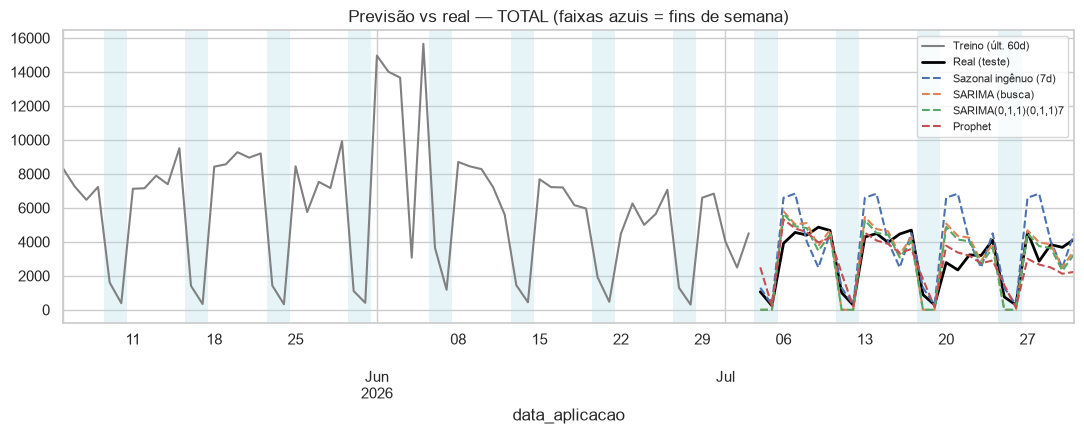

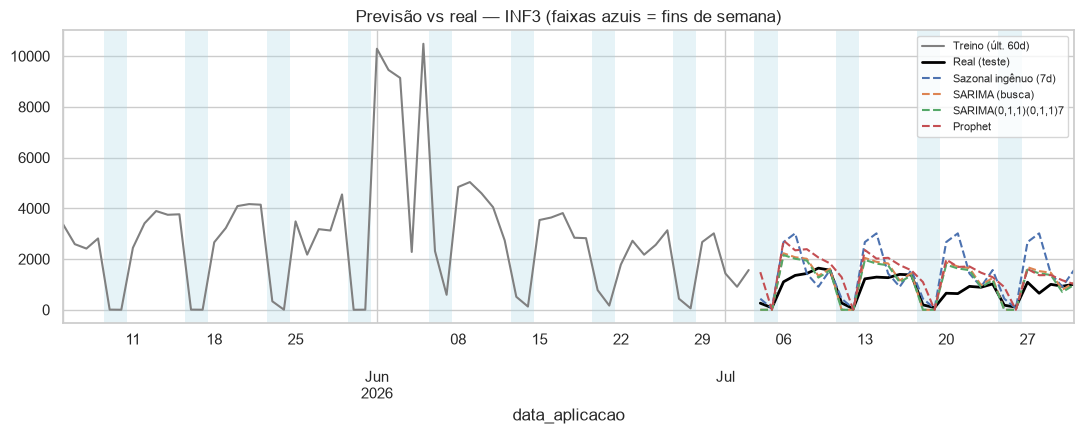

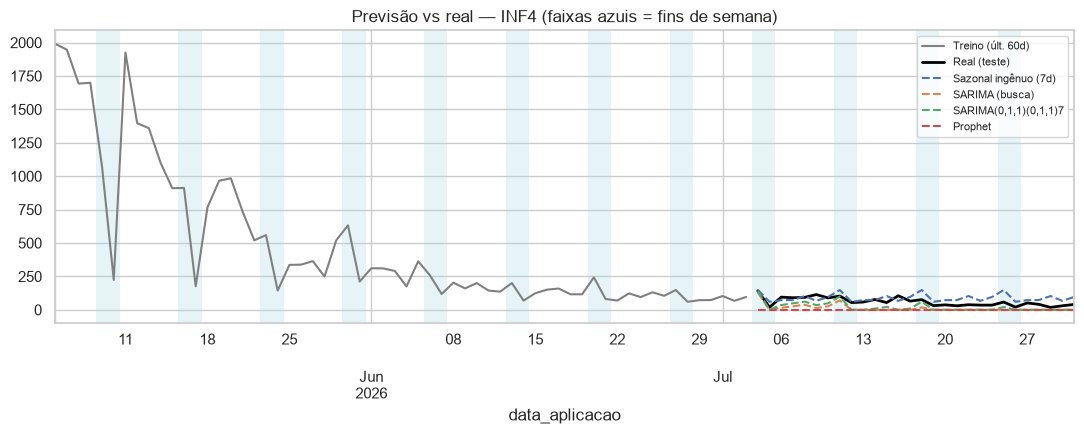

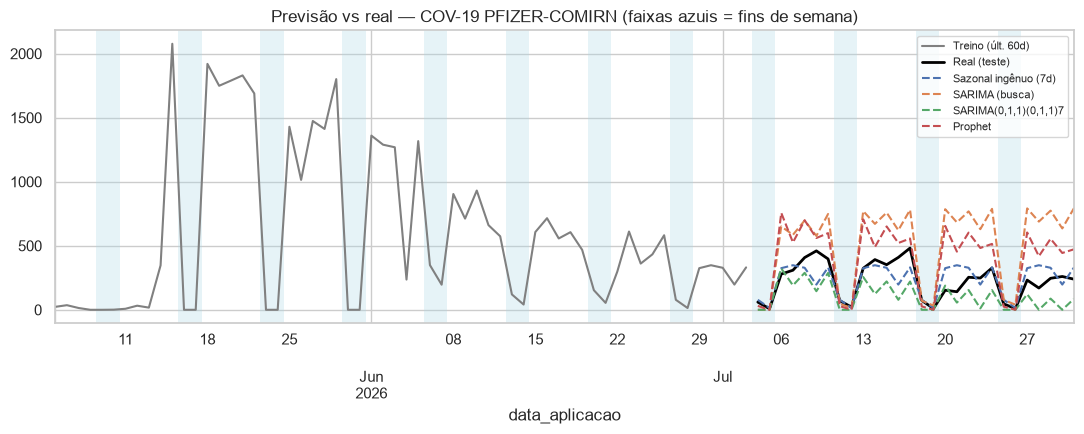

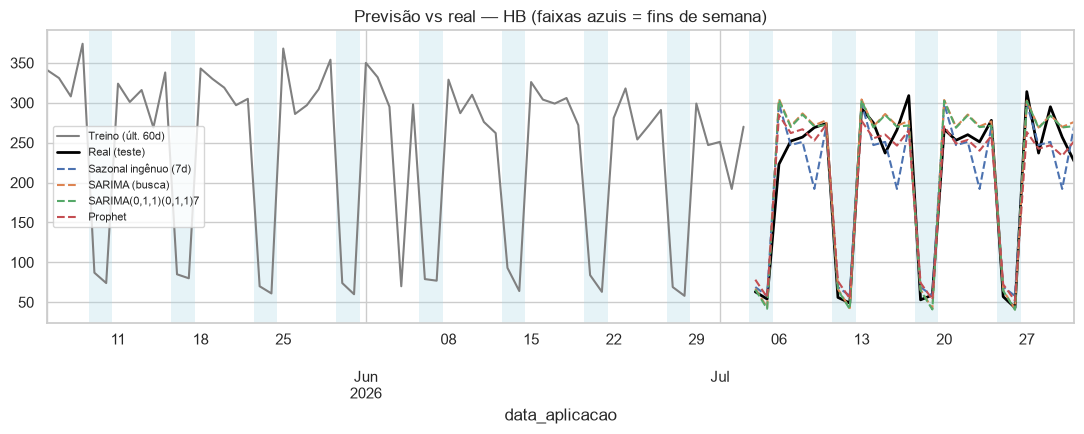

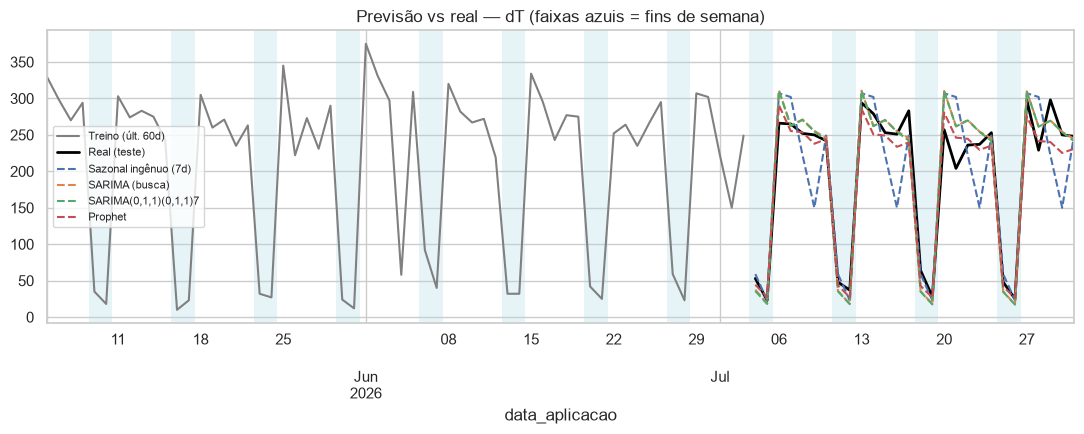

In [61]:
modelos_plot = ["Sazonal ingênuo (7d)", "SARIMA (busca)", "SARIMA(0,1,1)(0,1,1)7", "Prophet"]

for nome_serie, (tr, te, prevs) in previsoes.items():
    fig, ax = plt.subplots(figsize=(11, 4.5))
    tr.iloc[-60:].plot(ax=ax, color="gray", label="Treino (últ. 60d)")
    te.plot(ax=ax, color="black", lw=2, label="Real (teste)")
    for mod in modelos_plot:
        ax.plot(te.index, np.clip(prevs[mod], 0, None), "--", label=mod)

    # Faixas nos fins de semana (sábado=5, domingo=6)
    idx = tr.index[-60:].append(te.index)
    for d in idx[idx.dayofweek == 5]:
        ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(days=1, hours=12),
                   color="lightblue", alpha=0.3, lw=0)

    ax.set_title(f"Previsão vs real — {nome_serie} (faixas azuis = fins de semana)")
    ax.legend(fontsize=8)
    salvar(f"08_prev_{str(nome_serie)[:30].replace(' ','_').replace('/','-')}")
    plt.show(); plt.close(fig)


As séries têm uma sazonalidade semanal forte: o número de doses cai de forma brusca aos sábados e domingos, provavelmente porque muitas salas de vacinação funcionam menos nesses dias. Esse padrão justifica o uso do período sazonal de 7 dias nos modelos SARIMA e nos baselines sazonais. Também explica o desempenho ruim do modelo ingênuo, que, sem componente sazonal, erra sistematicamente nos fins de semana.

Os gráficos confirmam os resultados da Tabela X. Nas séries TOTAL, HB e dT, as previsões acompanham o padrão semanal observado. As curvas do Prophet e do SARIMA(0,1,1)(0,1,1)₇ ficam próximas, o que combina com a diferença pequena de RMSE entre eles (937,3 contra 941,5 no TOTAL). No INF3, os valores observados no teste ficam abaixo do nível do treino, o que indica uma redução na demanda, possivelmente ligada ao fim de uma campanha de vacinação. Como os modelos projetam o nível recente do treino, todos superestimam essa série, e o sMAPE passa de 80% em todos os casos. Na COV-19, o SARIMA escolhido por busca e o Prophet ficam acima dos valores reais durante o teste e têm os maiores erros da série (RMSE de 360,8 e 240,8). O SARIMA fixo (157,1) e o sazonal ingênuo (102,7) acompanham melhor o nível observado. Isso reforça que, com pouco volume, modelos mais flexíveis tendem a extrapolar tendências que não se mantêm.

## 11. Previsão futura com o melhor modelo (reajustado com a série completa)

In [62]:
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX

def prev_sarima_log(s, h):
    """SARIMA(0,1,1)(0,1,1)7 em escala log: a queda do fim de semana vira proporção
    (efeito multiplicativo), então a previsão nunca fica negativa."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = SARIMAX(np.log1p(s.astype(float)), order=(0,1,1),
                    seasonal_order=(0,1,1,SAZONALIDADE),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    return np.expm1(np.asarray(m.forecast(h)))

# Nomes exatos, iguais aos da tabela de métricas (etapa 10)
funcoes = {
    "Naive":                 lambda s, h: baseline_naive(s, h),
    "Sazonal ingênuo (7d)":  lambda s, h: baseline_sazonal(s, h),
    "Média dia-semana 4sem": lambda s, h: baseline_media_dow(s, h),
    "SARIMA (busca)":        lambda s, h: prev_sarima(s, h)[0],
    "SARIMA(0,1,1)(0,1,1)7": lambda s, h: prev_sarima_simples(s, h),
    "SARIMA log":            prev_sarima_log,
    "Prophet":               lambda s, h: prev_prophet(s, h),
}

# Exceções justificadas (ver texto do relatório):
#  - INF3: o SARIMA aditivo previa valores negativos no fim de semana -> versão em log
#  - TOTAL: o Prophet projetava queda de 44% sem base nos dados -> sazonal ingênuo
substituir = {"INF3": "SARIMA log", "TOTAL": "Sazonal ingênuo (7d)"}

In [63]:
futuro, resumo = {}, []
for _, r in melhor.iterrows():
    mod = substituir.get(r.serie, r.modelo)
    if mod not in funcoes:
        raise KeyError(f"Modelo desconhecido para {r.serie}: {mod!r}")

    s = series[r.serie]
    bruto = np.asarray(funcoes[mod](s, HORIZONTE), dtype=float)

    # Verificação: avisa se o modelo gerou negativos (em vez de esconder com o clip)
    n_neg = int((bruto < 0).sum())
    if n_neg:
        print(f"⚠ {r.serie}: {n_neg} valor(es) negativo(s) previsto(s) com {mod}")

    futuro[r.serie] = np.clip(bruto, 0, None).round()

    # Plausibilidade: nível previsto vs última semana observada
    ult_sem = s.iloc[-7:].sum()
    sem1, sem2 = futuro[r.serie][:7].sum(), futuro[r.serie][7:14].sum()
    resumo.append({"serie": r.serie,
                   "melhor no teste": r.modelo,
                   "modelo usado": mod,
                   "última semana": int(ult_sem),
                   "prev. semana 1": int(sem1),
                   "prev. semana 2": int(sem2),
                   "var. sem1 vs últ. (%)": round(100 * (sem1 / ult_sem - 1), 1)})

display(pd.DataFrame(resumo).set_index("serie"))

idx = pd.date_range(serie_total.index[-1] + pd.Timedelta(days=1), periods=HORIZONTE)
df_futuro = pd.DataFrame(futuro, index=idx)
df_futuro.index.name = "data"
display(df_futuro.head(14))
df_futuro.to_csv("../reports/previsao_proximas_semanas.csv")

,melhor no teste,modelo usado,última semana,prev. semana 1,prev. semana 2,var. sem1 vs últ. (%)
serie,,,,,,
COV-19 PFIZER-COMIRN,Sazonal ingênuo (7d),Sazonal ingênuo (7d),1202,1202,1202,0.0
HB,Prophet,Prophet,1430,1360,1327,-4.9
INF3,"SARIMA(0,1,1)(0,1,1)7",SARIMA log,4964,4333,3849,-12.7
INF4,Sazonal ingênuo (7d),Sazonal ingênuo (7d),258,258,258,0.0
TOTAL,Prophet,Sazonal ingênuo (7d),20145,20145,20145,0.0
dT,Prophet,Prophet,1396,1289,1268,-7.7


,COV-19 PFIZER-COMIRN,HB,INF3,INF4,TOTAL,dT
data,,,,,,
2026-08-01,46.0,70.0,165.0,58.0,756.0,43.0
2026-08-02,9.0,52.0,63.0,20.0,287.0,26.0
2026-08-03,232.0,262.0,821.0,51.0,4584.0,275.0
2026-08-04,170.0,242.0,682.0,41.0,2859.0,242.0
2026-08-05,246.0,247.0,866.0,18.0,3836.0,242.0
2026-08-06,260.0,235.0,827.0,30.0,3676.0,227.0
2026-08-07,239.0,252.0,909.0,40.0,4147.0,234.0
2026-08-08,46.0,69.0,146.0,58.0,756.0,42.0
2026-08-09,9.0,50.0,56.0,20.0,287.0,25.0


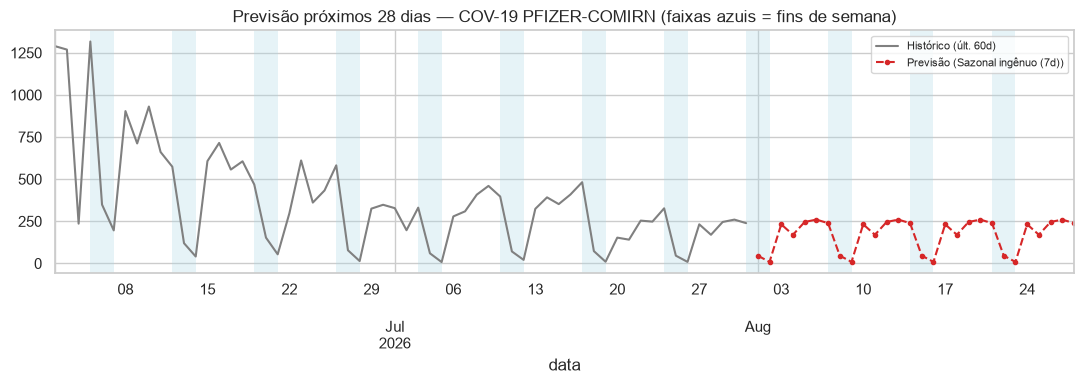

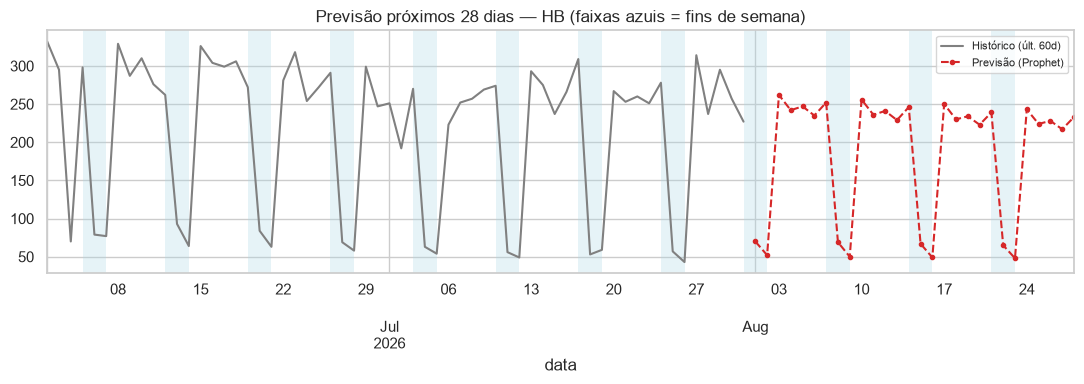

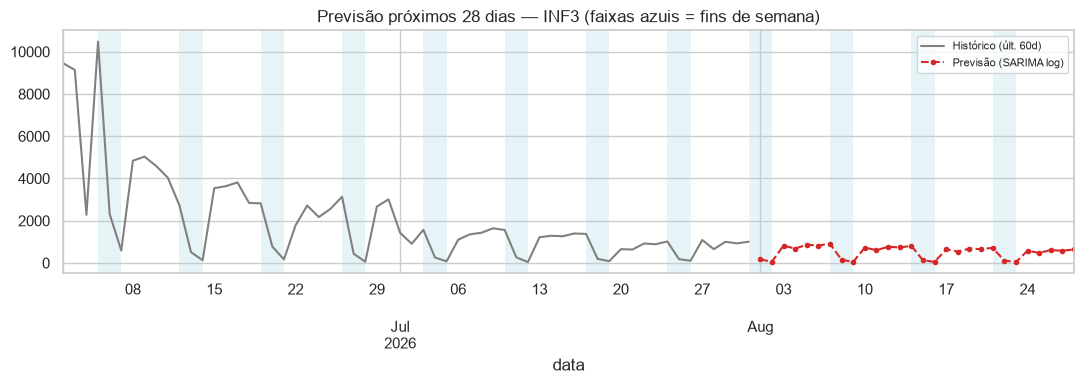

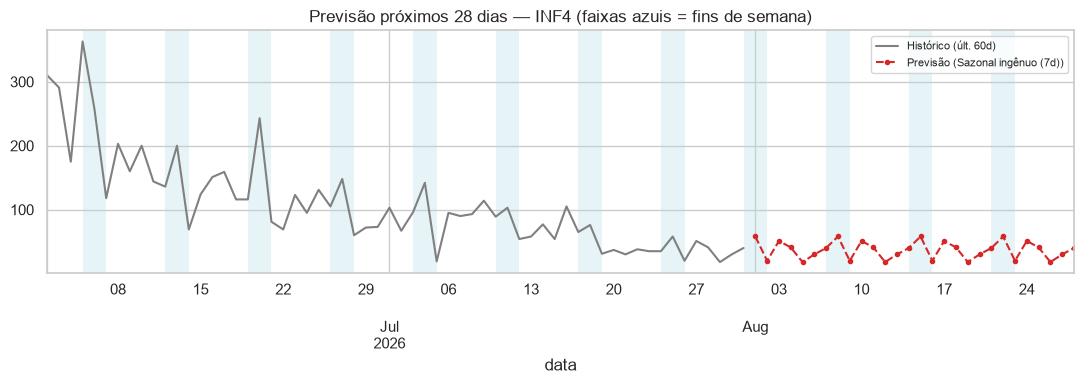

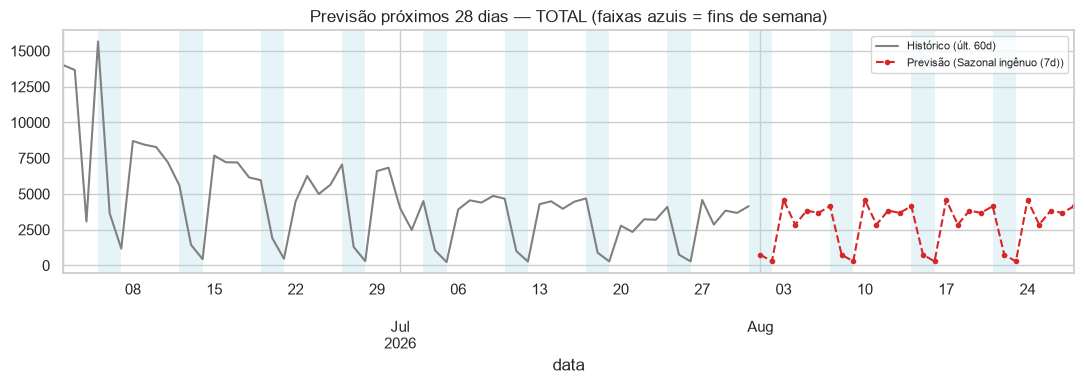

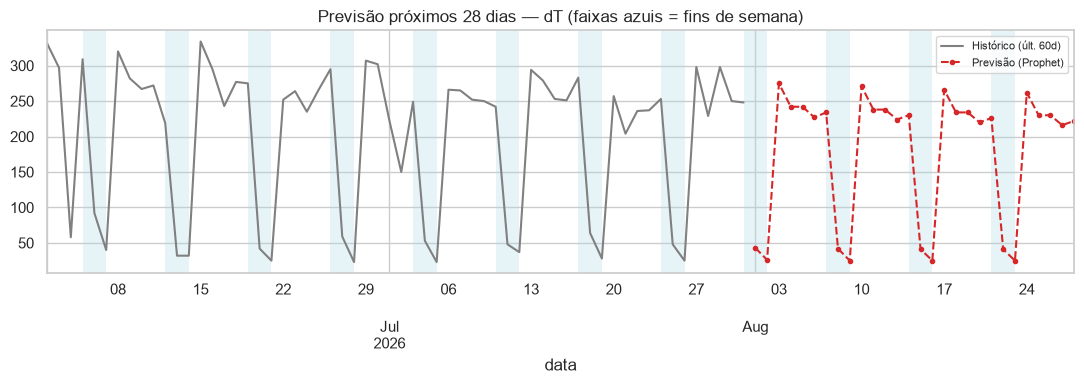

In [64]:
for nome in df_futuro.columns:
    s = series[nome]
    fig, ax = plt.subplots(figsize=(11, 4))
    s.iloc[-60:].plot(ax=ax, color="gray", label="Histórico (últ. 60d)")
    df_futuro[nome].plot(ax=ax, color="tab:red", ls="--", marker="o", ms=3,
                         label=f"Previsão ({substituir.get(nome, melhor.set_index('serie').loc[nome, 'modelo'])})")

    idx_all = s.index[-60:].append(df_futuro.index)
    for d in idx_all[idx_all.dayofweek == 5]:
        ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(days=1, hours=12),
                   color="lightblue", alpha=0.3, lw=0)

    ax.set_title(f"Previsão próximos {HORIZONTE} dias — {nome} (faixas azuis = fins de semana)")
    ax.legend(fontsize=8)
    salvar(f"11_futuro_{str(nome)[:30].replace(' ','_').replace('/','-')}")
    plt.show(); plt.close(fig)

Previsão futura

Foram previstos os 14 dias seguintes ao fim da base (01/08 a 14/08/2026). Como regra, cada série usou o modelo com menor RMSE no teste, reajustado com todo o histórico. Houve duas exceções, porque os modelos escolhidos produziram previsões implausíveis.

INF3: o SARIMA(0,1,1)(0,1,1)₇ previu valores negativos nos fins de semana, porque a queda do fim de semana é modelada como um valor fixo (efeito aditivo). Foi usada uma variante com transformação logarítmica, que trata essa queda como uma proporção e garante previsões positivas (RMSE no teste de 344,3, contra 503,1).
TOTAL: o Prophet teve o menor RMSE no teste (937,3). Mesmo assim, projetou uma queda de 44% em relação à última semana observada, seguida de mais 31% na semana seguinte, sem sinais nos dados que justificassem essa redução. As alternativas testadas também foram descartadas: o SARIMA aditivo, com e sem tendência, gerou valores negativos; a versão em log teve RMSE de 1263,1; e o Prophet com tendência suavizada teve RMSE de 5471,4. Optou-se pelo sazonal ingênuo (RMSE de 1803,5), que mantém o padrão da última semana observada.
Nas demais séries, foi usado o melhor modelo do teste: o Prophet no HB e no dT, e o sazonal ingênuo na COV-19 e no INF4.

A Tabela Y resume as previsões. TOTAL, COV-19 e INF4 mantêm o volume da última semana observada (20.145, 1.202 e 258 doses por semana). HB e dT têm quedas leves na primeira semana (−4,9% e −7,7%) e ficam quase estáveis na segunda. O INF3 continua em queda, com −12,7% na primeira semana (4.333 doses) e mais −11,2% na segunda (3.849 doses). Esse resultado é coerente com a redução já vista no período de teste, mas pressupõe que ela continue. Todas as previsões mantêm a sazonalidade semanal, com quedas acentuadas aos sábados e domingos. Nas séries modeladas pelo sazonal ingênuo, a previsão também repete irregularidades pontuais da última semana, como a quarta-feira baixa no INF4 (18 doses).

Limitações. As alternativas da previsão futura foram avaliadas no mesmo conjunto de teste depois da seleção inicial, então seus RMSE são otimistas. Com uma única janela de teste de 28 dias, a ordem entre os modelos também é sensível ao período escolhido. Os modelos não incluem feriados nem informações sobre campanhas de vacinação, que afetam fortemente a demanda. Como trabalho futuro, recomenda-se validar os modelos em várias janelas (rolling origin), usar a sazonalidade multiplicativa desde o início e incluir feriados e campanhas como variáveis externas

## 12. Interpretação e limitações

**Sazonalidade semanal.** Em todas as séries, a sazonalidade semanal é o padrão dominante, com quedas acentuadas aos sábados e domingos. Por isso, os baselines sazonais foram usados como referência mínima. O modelo ingênuo, sem sazonalidade, ficou entre os piores em todas as séries, o que confirma a importância desse componente.

**Modelos complexos nem sempre vencem os baselines.** Na COV-19 e no INF4, o sazonal ingênuo teve o menor RMSE no teste e superou o SARIMA e o Prophet. Nessas séries, com volume baixo e padrão semanal estável, repetir a última semana é tão bom quanto modelar a série, ou melhor. O Prophet foi o melhor no HB, no dT e no TOTAL, e o SARIMA(0,1,1)(0,1,1)₇ foi o melhor no INF3.

**RMSE baixo não garante uma previsão plausível.** Na previsão futura, dois modelos foram trocados:
- O SARIMA aditivo previu valores negativos nos fins de semana, porque trata a queda do fim de semana como um valor fixo. No INF3, foi usada a versão em log (efeito multiplicativo).
- No TOTAL, o Prophet projetou uma queda de 44% sem base nos dados. Foi usado o sazonal ingênuo.
Por isso, a escolha do modelo considerou a plausibilidade da previsão, e não só a métrica.

**Campanhas.** Campanhas (ex.: Influenza) geram picos e quedas que não se repetem, e a base tem menos de 1 ano de dados. Os modelos não "conhecem" campanhas futuras. A queda prevista no INF3 (−12,7% e −11,2% por semana) pressupõe que a redução recente continue. Uma possível melhoria é usar regressores de campanha e de feriados no Prophet.

**Atraso de registro.** Foi verificado se os últimos dias estavam subnotificados. A última semana da base (25 a 31/07) tem volumes normais, então nenhum dia foi descartado. Em atualizações futuras, essa verificação deve ser repetida.

**Validação.** Houve uma única janela de teste (28 dias), e as alternativas da etapa 11 foram avaliadas depois da seleção inicial. Assim, a ordem entre os modelos é sensível ao período escolhido, e parte dos RMSE é otimista. Recomenda-se fazer a validação em várias janelas (*rolling origin*).

**Escopo.** O modelo prevê **doses aplicadas**, e não cobertura vacinal. Não há denominador populacional, a mesma ressalva feita no clustering.
